# Decision Tree

Train and evaluate a Decision Tree classifier on the dataset, with feature auto-detection and standard metrics.

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from IPython.display import display
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder
import joblib

from schema_utils import detect_feature_columns, build_feature_matrix
print('Environment ready.')



Environment ready.


In [2]:
# 2. Data Loading - use train/test CSVs
import os
import pandas as pd
DATA_DIR = os.path.join('..','datasets')
TRAIN_PATH = os.path.join(DATA_DIR, 'training_data_train_cat.csv')
TEST_PATH = os.path.join(DATA_DIR, 'training_data_test_cat.csv')
if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
    raise FileNotFoundError("Missing train/test CSVs in ../datasets: training_data_train.csv and training_data_test.csv")
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
from schema_utils import detect_feature_columns
schema = detect_feature_columns(df_train)
if not schema['label_col']:
    raise ValueError('No label column detected. Expected one of: label/class/target')
label_col = schema['label_col']
print('Train size:', len(df_train), 'Test size:', len(df_test))
print('Train balance:', df_train[label_col].value_counts(normalize=True))
print('Test balance:', df_test[label_col].value_counts(normalize=True))



Train size: 1661 Test size: 483
Train balance: label
human      0.493076
nothing    0.338350
cat        0.168573
Name: proportion, dtype: float64
Test balance: label
human      0.432712
nothing    0.422360
cat        0.144928
Name: proportion, dtype: float64


In [3]:
# 3-4. Features + Split (pre-split train/test, train-only fit)
import numpy as np
from schema_utils import build_feature_matrix
feature_cols = schema['classic_feature_cols']
X_train_all = build_feature_matrix(df_train, feature_cols)
X_test_all = build_feature_matrix(df_test, feature_cols)
# Fill NaNs using training medians
train_medians = np.nanmedian(X_train_all, axis=0)
X_train_all = np.where(np.isnan(X_train_all), train_medians, X_train_all)
X_test_all = np.where(np.isnan(X_test_all), train_medians, X_test_all)
# Labels
y_str_train = df_train[label_col].astype(str).values
y_str_test = df_test[label_col].astype(str).values
from sklearn.preprocessing import LabelEncoder, StandardScaler
le = LabelEncoder()
y_train = le.fit_transform(y_str_train)
y_test = le.transform(y_str_test)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_all)
X_test = scaler.transform(X_test_all)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Classes:', list(le.classes_))



Train shape: (1661, 46) Test shape: (483, 46)
Classes: ['cat', 'human', 'nothing']


In [4]:

from sklearn.tree import DecisionTreeClassifier, plot_tree

# Create, train, evaluate
clf = DecisionTreeClassifier(max_depth=10, min_samples_leaf=10, class_weight='balanced', random_state=42)
clf.fit(X_train, y_train)

training_accuracy = clf.score(X_train, y_train)
test_accuracy = clf.score(X_test, y_test)
print('Training accuracy:', round(training_accuracy, 4))
print('Test accuracy:', round(test_accuracy, 4))

y_pred = clf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix:', cm)
print('Classification report:', classification_report(y_test, y_pred, target_names=list(le.classes_)))
# Quick cat recall check if 'cat' present
if 'cat' in le.classes_:
    cat_idx = list(le.classes_).index('cat')
    cat_support = int((y_test == cat_idx).sum())
    cat_tp = int(((y_test == cat_idx) & (y_pred == cat_idx)).sum())
    cat_recall = (cat_tp / cat_support) if cat_support > 0 else float('nan')
    print(f"Cat support: {cat_support}, Cat recall: {cat_recall:.3f}")


Training accuracy: 1.0
Test accuracy: 0.9979
Confusion matrix: [[ 70   0   0]
 [  0 208   1]
 [  0   0 204]]
Classification report:               precision    recall  f1-score   support

         cat       1.00      1.00      1.00        70
       human       1.00      1.00      1.00       209
     nothing       1.00      1.00      1.00       204

    accuracy                           1.00       483
   macro avg       1.00      1.00      1.00       483
weighted avg       1.00      1.00      1.00       483

Cat support: 70, Cat recall: 1.000


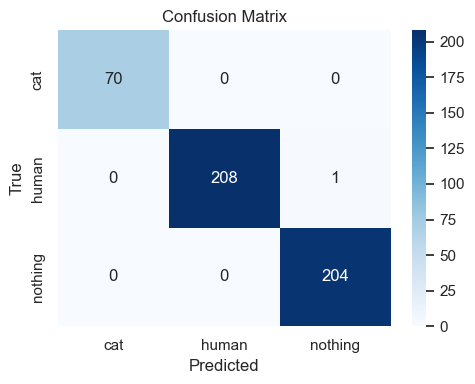

              precision    recall  f1-score   support

         cat       1.00      1.00      1.00        70
       human       1.00      1.00      1.00       209
     nothing       1.00      1.00      1.00       204

    accuracy                           1.00       483
   macro avg       1.00      1.00      1.00       483
weighted avg       1.00      1.00      1.00       483



In [5]:

# Confusion Matrix - Visualize mistakes
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(le.classes_), yticklabels=list(le.classes_))
plt.title('Confusion Matrix')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()
print(classification_report(y_test, y_pred, target_names=list(le.classes_)))


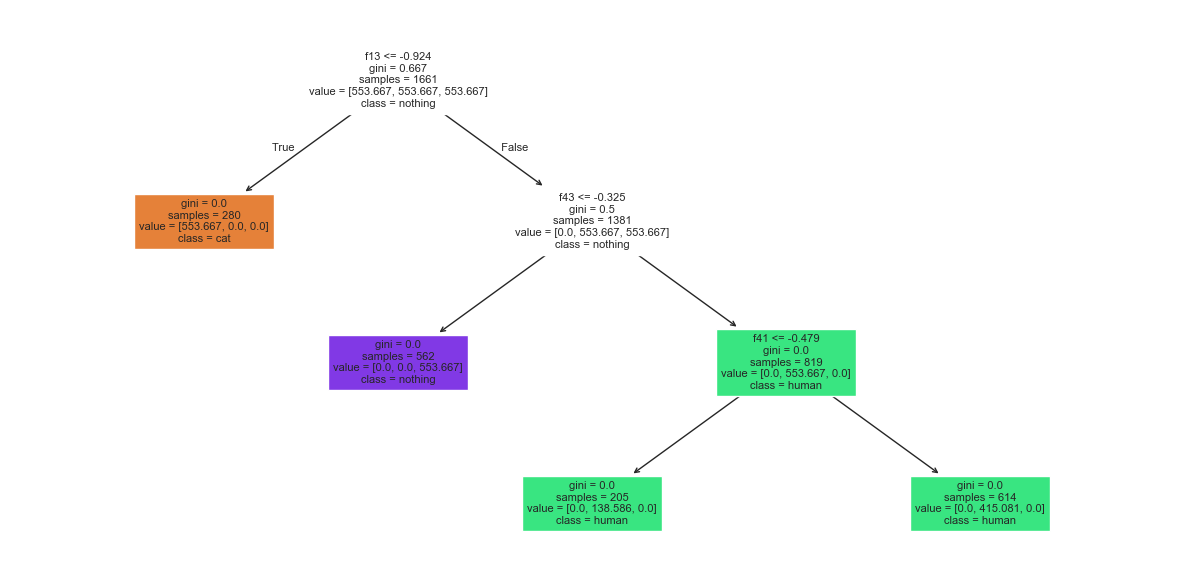

In [6]:

# Optional: visualize the tree (may be large)
plt.figure(figsize=(12, 6))
plot_tree(clf, max_depth=3, feature_names=feature_cols, class_names=list(le.classes_), filled=True, fontsize=8)
plt.tight_layout()
plt.show()


In [7]:

# Save model
os.makedirs(os.path.join('..','models'), exist_ok=True)
model_path = os.path.join('..','models','DecisionTree_cat.pkl')
joblib.dump({'model': clf, 'label_encoder': le, 'feature_cols': feature_cols}, model_path)
print('Saved to', model_path)


Saved to ../models/DecisionTree_cat.pkl
